# Comparing solutions

You can't easily find the size of the solution space, because you have degenerate variables. 

**Conclusion**: The best solution is to sample the solution space and find the variability in the solutions.



In [3]:
import reframed
import cobra
import pandas as pd
import numpy as np
from os import listdir
import warnings
import seaborn as sns
from collections import OrderedDict
import json
import os

In [26]:
import math

### Run SteadierSample

## Find most important from small dataset

**Find important keys in main sols**

### Read data 

In [4]:
direct = os.listdir("../output/Venturelli2018/performance_statistics/")

In [5]:
dfs = []
for d in direct:
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/performance_statistics/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

In [17]:
dfs_tot = pd.concat(dfs,axis=1)

dfs_tot = dfs_tot.T.drop_duplicates().T

dfs_tot.columns = np.arange(0,dfs_tot.shape[1])
dfs_tot

0     \
Collinsella_aerofaciens_ATCC_25986  M_nzp__91__e__93__         0.000129   
Blautia_hydrogenotrophica_DSM_10507 M_gal__91__e__93__         0.000000   
Bacteroides_uniformis_ATCC_8492     M_R_7oh_warf__91__e__93__  0.000000   
Desulfovibrio_piger_ATCC_29098      M_alagly__91__e__93__      0.000000   
Collinsella_aerofaciens_ATCC_25986  M_man__91__e__93__         0.000000   
...                                                                 ...   
Bacteroides_vulgatus_ATCC_8482      M_dextrin__91__e__93__     0.000000   
                                    M_arabinoxyl__91__e__93__  0.000000   
Desulfovibrio_piger_ATCC_29098      M_glycys__91__e__93__     -0.000008   
Bacteroides_vulgatus_ATCC_8482      M_12ppd_S__91__e__93__     0.000000   
Bacteroides_ovatus_ATCC_8483        M_rmn__91__e__93__         0.000000   

                                                                   1     2     \
Collinsella_aerofaciens_ATCC_25986  M_nzp__91__e__93__         0.000000   0.0   
Blautia_hydrogenotrophica_DSM_10507 M_gal__91__e__93__         0.000000   0.0   
Bacteroides_uniformis_ATCC_8492     M_R_7oh_warf__91__e__93__  0.000000   0.0   
Desulfovibrio_piger_ATCC_29098      M_alagly__91__e__93__      0.000000   0.0   
Collinsella_aerofaciens_ATCC_25986  M_man__91__e__93__         0.000000   0.0   
...                                                                 ...   ...   
Bacteroides_vulgatus_ATCC_8482      M_dextrin__91__e__93__    -0.000013   0.0   
                                    M_arabinoxyl__91__e__93__  0.000000   0.0   
Desulfovibrio_piger_ATCC_29098      M_glycys__91__e__93__      0.000000   0.0   
Bacteroides_vulgatus_ATCC_8482      M_12ppd_S__91__e__93__     0.000000   0.0   
Bacteroides_ovatus_ATCC_8483        M_rmn__91__e__93__         0.000375   0.0   

                                                                   3     \
Collinsella_aerofaciens_ATCC_25986  M_nzp__91__e__93__         0.000000   
Blautia_hydrogenotrophica_DSM_10507 M_gal__91__e__93__         0.000000   
Bacteroides_uniformis_ATCC_8492     M_R_7oh_warf__91__e__93__  0.000000   
Desulfovibrio_piger_ATCC_29098      M_alagly__91__e__93__      0.000000   
Collinsella_aerofaciens_ATCC_25986  M_man__91__e__93__         0.000000   
...                                                                 ...   
Bacteroides_vulgatus_ATCC_8482      M_dextrin__91__e__93__    -0.000005   
                                    M_arabinoxyl__91__e__93__ -0.000017   
Desulfovibrio_piger_ATCC_29098      M_glycys__91__e__93__     -0.000008   
Bacteroides_vulgatus_ATCC_8482      M_12ppd_S__91__e__93__     0.000000   
Bacteroides_ovatus_ATCC_8483        M_rmn__91__e__93__         0.000000   

                                                                   4     \
Collinsella_aerofaciens_ATCC_25986  M_nzp__91__e__93__         0.000000   
Blautia_hydrogenotrophica_DSM_10507 M_gal__91__e__93__         0.000000   
Bacteroides_uniformis_ATCC_8492     M_R_7oh_warf__91__e__93__  0.000000   
Desulfovibrio_piger_ATCC_29098      M_alagly__91__e__93__      0.000000   
Collinsella_aerofaciens_ATCC_25986  M_man__91__e__93__        -0.000099   
...                                                                 ...   
Bacteroides_vulgatus_ATCC_8482      M_dextrin__91__e__93__     0.000000   
                                    M_arabinoxyl__91__e__93__  0.000000   
Desulfovibrio_piger_ATCC_29098      M_glycys__91__e__93__      0.000000   
Bacteroides_vulgatus_ATCC_8482      M_12ppd_S__91__e__93__     0.000000   
Bacteroides_ovatus_ATCC_8483        M_rmn__91__e__93__         0.000000   

                                                                   5     6     \
Collinsella_aerofaciens_ATCC_25986  M_nzp__91__e__93__         0.000129   0.0   
Blautia_hydrogenotrophica_DSM_10507 M_gal__91__e__93__         0.000000   0.0   
Bacteroides_uniformis_ATCC_8492     M_R_7oh_warf__91__e__93__  0.000000   0.0   
Desulfovibrio_piger_ATCC_29098      M_alagly__91__e__93__      0.00

### Comparing solutions

In [33]:
sample_size = 20

number = math.floor(dfs_tot.shape[1]/sample_size)

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})

In [34]:
mean

set0  \
Collinsella_aerofaciens_ATCC_25986  M_nzp__91__e__93__        -2.730021e-04   
Blautia_hydrogenotrophica_DSM_10507 M_gal__91__e__93__        -4.382470e-06   
Bacteroides_uniformis_ATCC_8492     M_R_7oh_warf__91__e__93__  0.000000e+00   
Desulfovibrio_piger_ATCC_29098      M_alagly__91__e__93__      0.000000e+00   
Collinsella_aerofaciens_ATCC_25986  M_man__91__e__93__        -1.604704e-04   
...                                                                     ...   
Bacteroides_vulgatus_ATCC_8482      M_dextrin__91__e__93__    -8.929064e-07   
                                    M_arabinoxyl__91__e__93__ -1.126416e-05   
Desulfovibrio_piger_ATCC_29098      M_glycys__91__e__93__     -3.263257e-06   
Bacteroides_vulgatus_ATCC_8482      M_12ppd_S__91__e__93__     0.000000e+00   
Bacteroides_ovatus_ATCC_8483        M_rmn__91__e__93__         1.608046e-04   

                                                                       set1  \
Collinsella_aerofaciens_ATCC_25986  M_nzp__91__e__93__         9.160835e-05   
Blautia_hydrogenotrophica_DSM_10507 M_gal__91__e__93__        -8.764939e-06   
Bacteroides_uniformis_ATCC_8492     M_R_7oh_warf__91__e__93__  0.000000e+00   
Desulfovibrio_piger_ATCC_29098      M_alagly__91__e__93__     -1.651855e-06   
Collinsella_aerofaciens_ATCC_25986  M_man__91__e__93__        -2.356502e-04   
...                                                                     ...   
Bacteroides_vulgatus_ATCC_8482      M_dextrin__91__e__93__    -5.277125e-07   
                                    M_arabinoxyl__91__e__93__ -9.761200e-06   
Desulfovibrio_piger_ATCC_29098      M_glycys__91__e__93__     -3.942860e-06   
Bacteroides_vulgatus_ATCC_8482      M_12ppd_S__91__e__93__    -2.452811e-05   
Bacteroides_ovatus_ATCC_8483        M_rmn__91__e__93__         7.372278e-05   

                                                                   set2  \
Collinsella_aerofaciens_ATCC_25986  M_nzp__91__e__93__        -0.001521   
Blautia_hydrogenotrophica_DSM_10507 M_gal__91__e__93__        -0.000004   
Bacteroides_uniformis_ATCC_8492     M_R_7oh_warf__91__e__93__  0.000000   
Desulfovibrio_piger_ATCC_29098      M_alagly__91__e__93__     -0.000002   
Collinsella_aerofaciens_ATCC_25986  M_man__91__e__93__        -0.000219   
...                                                                 ...   
Bacteroides_vulgatus_ATCC_8482      M_dextrin__91__e__93__    -0.000040   
                                    M_arabinoxyl__91__e__93__ -0.000012   
Desulfovibrio_piger_ATCC_29098      M_glycys__91__e__93__     -0.000007   
Bacteroides_vulgatus_ATCC_8482      M_12ppd_S__91__e__93__     0.000000   
Bacteroides_ovatus_ATCC_8483        M_rmn__91__e__93__         0.000003   

                                                                   set3  \
Collinsella_aerofaciens_ATCC_25986  M_nzp__91__e__93__         0.000076   
Blautia_hydrogenotrophica_DSM_10507 M_gal__91__e__93__        -0.000009   
Bacteroides_uniformis_ATCC_8492     M_R_7oh_warf__91__e__93__  0.000000   
Desulfovibrio_piger_ATCC_29098      M_alagly__91__e__93__      0.000000   
Collinsella_aerofaciens_ATCC_25986  M_man__91__e__93__        -0.000051   
...                                                                 ...   
Bacteroides_vulgatus_ATCC_8482      M_dextrin__91__e__93__    -0.000015   
                                    M_arabinoxyl__91__e__93__ -0.000012   
Desulfovibrio_piger_ATCC_29098      M_glycys__91__e__93__     -0.000016   
Bacteroides_vulgatus_ATCC_8482      M_12ppd_S__91__e__93__    -0.000486   
Bacteroides_ovatus_ATCC_8483        M_rmn__91__e__93__         0.000067   

                                                                   set4  \
Collinsella_aerofaciens_ATCC_25986  M_nzp__91__e__93__         0.000036   
Blautia_hydrogenotrophica_DSM_10507 M_gal__91__e__93__         0.000000   
Bacteroides_uniformis_ATCC_8492     M_R_7oh_warf__91__e__93__  0.006293   
Desulfovibrio_piger_ATCC_29098      M_alagly__91__e__93__      0.000000

In [107]:
sample_size = 10

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(166.42534277307064)

In [86]:
sample_size = 20

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(425.9104612836755)

In [87]:
sample_size = 50

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(164.7028415752127)

In [88]:
sample_size = 100

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(168.18748810373765)

In [89]:
sample_size = 200

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(98.7192582103845)

In [90]:
sample_size = 400

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(94.85368700653677)

In [91]:
sample_size = 800

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(150.06340660204035)

In [96]:
sample_size = 900

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(163.08331344398636)

In [92]:
sample_size = 1000

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(47.64508592654771)

In [93]:
sample_size = 1200

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(42.49187327683128)

In [94]:
sample_size = 1400

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(44.57046951748426)

In [95]:
sample_size = 1500

#number = math.floor(dfs_tot.shape[1]/sample_size)

number=3

mean = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


equal_zero= mean.sum(axis=1).apply(abs).sort_values() <1e-6

mean = mean.loc[~equal_zero]

cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 

#mean.T.apply(cv).sort_values(ascending=False).head(500)

mean.T.apply(cv).mean()

np.float64(45.99775865211904)

### Test for variable set size

In [160]:
np.logspace(1,3.15,20)

array([  10.        ,   12.97650967,   16.83898032,   21.8511191 ,
         28.35512583,   36.79505646,   47.7471406 ,   61.95912318,
         80.40131611,  104.33284561,  135.387618  ,  175.68587343,
        227.97894356,  295.83709659,  383.8932945 ,  498.15950486,
        646.43716325,  838.84981005, 1088.53426726, 1412.53754462])

In [189]:
statistics = {}
for n in np.logspace(1,3.15,20):
    sample_size = int(n)

    number = math.floor(dfs_tot.shape[1]/sample_size)


    data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


    equal_zero= data.sum(axis=1).apply(abs).sort_values() <1e-6

    data = data.loc[~equal_zero]

    cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
    data = data.T.apply(cv)
    
    
    median = data.median()
    mean = data.mean()
    max_ = data.max()
    min_ = data.min()
    statistics[sample_size] = {"mean":mean,
                               "median":median,
                               "max":max_,
                               "min":min_}

<Axes: >

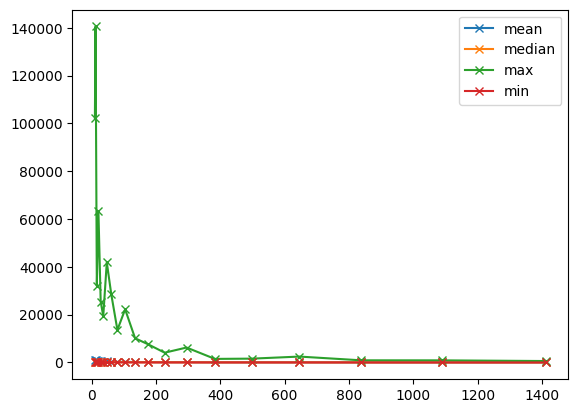

In [190]:
statistics_df = pd.DataFrame(statistics).T
statistics_df.plot(marker="x")

<Axes: >

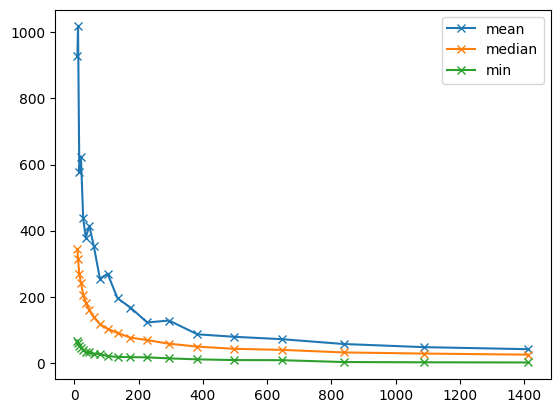

In [191]:
statistics_df[[column for column in statistics_df.columns if column!="max" ]].plot(marker="x")